# **TP Noté M2 Machine Learning** - Prétot Cécilia M2B IA - 12/10/2026

---
# **PARTIE 1 : "imports85".csv**

***1) On utilise les données « imports85 » fournies. On souhaite prédire la variable « price » à l’aide des autres variables. Proposer plusieurs algorithmes de prédiction de cette variable et les comparer.***

1. Je commence par charger les données.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/drive/MyDrive/Machine Learning/evaluation/imports85.csv", sep=";", decimal=',', na_values='NA')
print(df.shape)
df.head()

(205, 26)


,symboling,normalizedLosses,make,fuelType,aspiration,numOfDoors,bodyStyle,driveWheels,engineLocation,wheelBase,...,engineSize,fuelSystem,bore,stroke,compressionRatio,horsepower,peakRpm,cityMpg,highwayMpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


2. J'explore les données.

In [ ]:
quanti = df.select_dtypes(include='number').columns.tolist()
quali = df.select_dtypes(exclude='number').columns.tolist()
print('Variables quantitatives (', len(quanti), ') :', quanti)
print()
print('Variables qualitatives (', len(quali), ') :', quali)
print()
df.info()

Variables quantitatives ( 16 ) : ['symboling', 'normalizedLosses', 'wheelBase', 'length', 'width', 'height', 'curbWeight', 'engineSize', 'bore', 'stroke', 'compressionRatio', 'horsepower', 'peakRpm', 'cityMpg', 'highwayMpg', 'price']

Variables qualitatives ( 10 ) : ['make', 'fuelType', 'aspiration', 'numOfDoors', 'bodyStyle', 'driveWheels', 'engineLocation', 'engineType', 'numOfCylinders', 'fuelSystem']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   symboling         205 non-null    int64  
 1   normalizedLosses  164 non-null    float64
 2   make              205 non-null    object 
 3   fuelType          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   numOfDoors        203 non-null    object 
 6   bodyStyle         205 non-null    object 
 7   driveWheels       205 non-null    object 
 8   engineLocat

→ Je vois que ma cible "price" est quantitative.

→ Les données explicatives sont qualitatives, je dois les transformer en variables indcatrices avec get_dummies.

3. Je réalise ensuite quelques statistiques descriptives sur les données.

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
symboling,205.0,0.83,1.25,-2.00,0.00,1.00,2.00,3.00
normalizedLosses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00
wheelBase,205.0,98.76,6.02,86.60,94.50,97.00,102.40,120.90
length,205.0,174.05,12.34,141.10,166.30,173.20,183.10,208.10
width,205.0,65.91,2.15,60.30,64.10,65.50,66.90,72.30
height,205.0,53.72,2.44,47.80,52.00,54.10,55.50,59.80
curbWeight,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2935.00,4066.00
engineSize,205.0,126.91,41.64,61.00,97.00,120.00,141.00,326.00
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17


count      201.0
mean     13207.1
std       7947.1
min       5118.0
25%       7775.0
50%      10295.0
75%      16500.0
max      45400.0
Name: price, dtype: float64

Asymétrie (skewness) de price      : 1.81
Asymétrie (skewness) de log(price) : 0.68


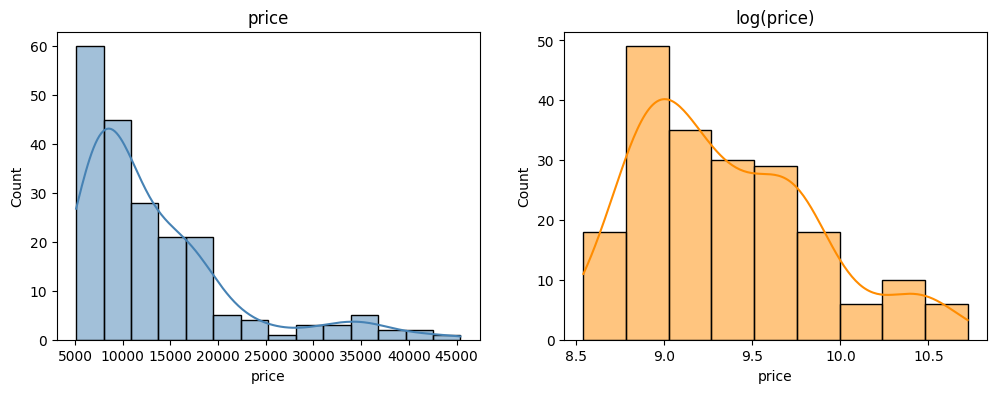

In [ ]:
print(df['price'].describe().round(1))
print()
print('Asymétrie (skewness) de price      :', round(df['price'].skew(), 2))
print('Asymétrie (skewness) de log(price) :', round(np.log(df['price']).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price'].dropna(), kde=True, ax=ax[0], color='steelblue'); ax[0].set_title('price')
sns.histplot(np.log(df['price'].dropna()), kde=True, ax=ax[1], color='darkorange'); ax[1].set_title('log(price)')
plt.show()

→ On peut observer que la distribution de la variable "price" est assez asymétrique (skew).

→ Je passe donc au log(price) pour avoir une asymétrie plus faible (mais c'est toujours pas parfait).

→ Il faudra que je repasse en exponentielle à la fin pour les calculs de métriques.

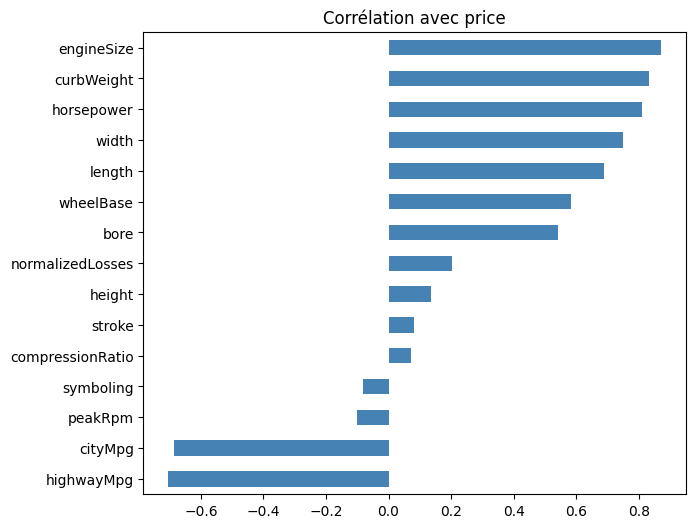

In [ ]:
# Corrélation des variables numériques avec le prix
correl = df[quanti].corr()['price'].drop('price').sort_values()
correl.plot(kind='barh', figsize=(7, 6), color='steelblue')
plt.title('Corrélation avec price'); plt.show()

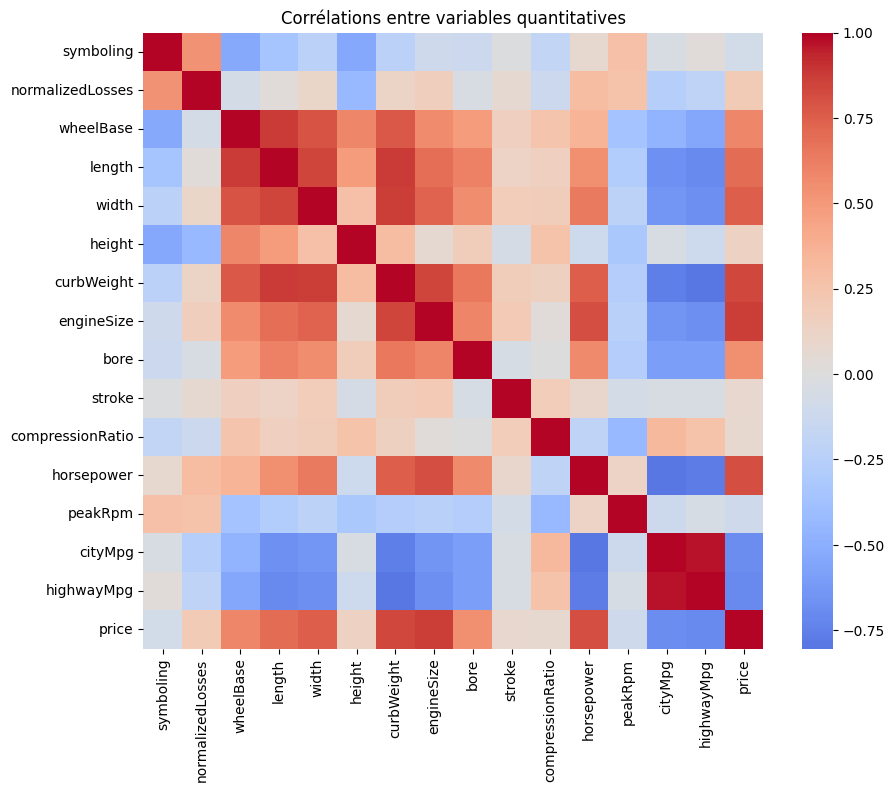

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[quanti].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Corrélations entre variables quantitatives')
plt.show()

→ Ici, curbWeight, engineSize et horsepower sont très corrélées au prix.

4. J'analyse maintenant la qualité des données : est-ce qu'il manque des valeurs.


In [ ]:
manquants = df.isna().sum()
manquants = manquants[manquants > 0]
pd.DataFrame({'nb manquants': manquants, '% manquants': (manquants / len(df) * 100).round(1)})

,nb manquants,% manquants
normalizedLosses,41,20.0
numOfDoors,2,1.0
bore,4,2.0
stroke,4,2.0
horsepower,2,1.0
peakRpm,2,1.0
price,4,2.0


→ J'osbserve que certaines lignes ont pour valeurs manquantes la cible. Je ne peux pas inventer la valeur cible donc ces lignes seront supprimées.

→ Pour les lignes dont la valeur manquante est numOfDoors, je vais emputer par le mode, la valeur la plus fréquente.

→ Pour la colonne normalizedLosses, je me permet de retirer la colonne du dataset car il y a peu de corrélation avec le price et supprimer les lignes reviendrait à supprimer 20% du dataset ce qui est beaucoup trop.

→ Pour les lignes restantes dont des variables explicatives sont manquantes, je peux remplacer par la médiane. Je remplacerai par la médianne après avoir séparé mon dataset en train et test, car je ne souhaite pas que la médiane soit calculée à partir de lignes qui feront parti du test dans le futur.

In [ ]:
df_clean = df.dropna(subset=['price']).copy()           # on retire les lignes sans prix
df_clean = df_clean.drop(columns=['normalizedLosses'])  # trop de manquants
df_clean['numOfDoors'] = df_clean['numOfDoors'].fillna(df_clean['numOfDoors'].mode()[0])

print('Lignes restantes :', df_clean.shape[0])
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])

Lignes restantes : 201
bore          4
stroke        4
horsepower    2
peakRpm       2
dtype: int64


→ On avait au départ 205 lignes, maintenant 201 ce qui est correcte.

→ Les colonnes qui ont encore des valeurs manquantes seront emputées plus loin par la médiane donc c'est normal qu'elles apparaissent encore ici.

5. Je passe maintenant au découpage en Train/Test, à l'imputation et à la standardisation des données.

→ Je vais découper mes données en 80% apprentissage et 20% test.

→ Je vais imputer par la moyenne les valeurs manquantes.

→ Je vais standardiser car cela est ensentiel pour les algorithmes de Ridge et Lasso traités plus loin.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

y = np.log(df_clean['price'])                       # cible transformée en log
X = pd.get_dummies(df_clean.drop(columns=['price']), drop_first=True).astype(float) #variables qualitatives transofrmées en variables indicatrices

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #découpage de mon dataset en train/test

# imputation par la médiane du TRAIN
medianes = X_train.median() #la médiane n'est calculée que sur le train comme je l'ai expliquée plus haut
X_train = X_train.fillna(medianes) #j'impute les données manquantes du train
X_test = X_test.fillna(medianes) #j'impute les données manquantes du test

# standardisation (pour les modèles linéaires: Ridge et Lasso)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# vraie valeur de la cible dans son unité d'origine (pour calculer les métriques après)
reel_test = np.exp(y_test)

print('Variables explicatives après encodage :', X.shape[1])
print('Train :', X_train.shape[0], 'lignes | Test :', X_test.shape[0], 'lignes')

# tableaux qui vont stocker les résultats
resultats = []
preds = pd.DataFrame({'Réel': reel_test.values})

Variables explicatives après encodage : 63
Train : 160 lignes | Test : 41 lignes


6. Je m'occupe ensuite des métriques d'évaluation de la régression.

→ Toutes ces métriques seront calculées dans l'unité d'origine de la cible price, donc je dois utiliser np.exp(log(price)).

→ Les métriques de la régression sont MAE, R² et RMSE.

In [ ]:
def evaluer(nom, y_reel, y_pred, tableau):
  rmse = np.sqrt(mean_squared_error(y_reel, y_pred))
  mae = mean_absolute_error(y_reel, y_pred)
  r2 = r2_score(y_reel, y_pred)
  tableau.append({"Modèle" : nom, "MAE" : mae, "R²" : r2, "RMSE" : rmse})
  print(f"{nom} -> RMSE = {rmse:.2f} | MAE = {mae:.2f} | R² = {r2:.3f}")

7. Je peux maintenant passer au modèle 1 : la régression linéaire.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lin = LinearRegression().fit(X_train_sc, y_train)
pred_lin = np.exp(lin.predict(X_test_sc))
evaluer('Régression linéaire', reel_test, pred_lin, resultats)
preds['Régression linéaire'] = pred_lin

Régression linéaire -> RMSE = 2960.90 | MAE = 1749.87 | R² = 0.928


8. Je passe ensuite au modèle 2 : le modèle Ridge (pénalisation L2).

→ Ce modèle à un hyperparamètre à régler : alpha .

→ Pour trouver le alpha optimal : RidgeCV teste 50 valeurs de  α  (de 0,001 à 1000 par exemple) et garde celle qui donne la meilleure validation croisée à 5 plis sur le train.

In [ ]:
from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_sc, y_train)
print('alpha optimal (Ridge) :', round(ridge.alpha_, 4))

pred_ridge = np.exp(ridge.predict(X_test_sc))
evaluer('Ridge', reel_test, pred_ridge, resultats)
preds['Ridge'] = pred_ridge

alpha optimal (Ridge) : 33.9322
Ridge -> RMSE = 2669.04 | MAE = 1578.02 | R² = 0.942


9. Je passe ensuite au modèle 3 : Lasso (pénalisation L1).

→ Lasso choisit également son hyperparamètre alpha par validation croisé sur 5 plis.

In [ ]:
from sklearn.linear_model import LassoCV

lasso = LassoCV(cv=5, random_state=42, max_iter=50000).fit(X_train_sc, y_train)
print('alpha optimal (Lasso) :', round(lasso.alpha_, 5))

nb_non_nuls = int(np.sum(lasso.coef_ != 0))
print('Variables conservées :', nb_non_nuls, 'sur', X_train_sc.shape[1])

pred_lasso = np.exp(lasso.predict(X_test_sc))
evaluer('Lasso', reel_test, pred_lasso, resultats)
preds['Lasso'] = pred_lasso

# variables retenues par le Lasso (coefficient != 0)
coef_lasso = pd.Series(lasso.coef_, index=X_train.columns)
print(coef_lasso[coef_lasso != 0].sort_values(key=abs, ascending=False).head(10))

alpha optimal (Lasso) : 0.00624
Variables conservées : 31 sur 63
Lasso -> RMSE = 2183.53 | MAE = 1380.93 | R² = 0.961
curbWeight             0.211484
width                  0.065535
make_bmw               0.062129
driveWheels_rwd        0.050761
cityMpg               -0.038378
fuelSystem_2bbl       -0.036761
make_peugot           -0.033844
make_porsche           0.032945
make_audi              0.032592
engineLocation_rear    0.029851
dtype: float64


10. Je passe ensuite au modèle 4 : l'arbre de décision

→ Ce modèle n'utilise pas les données standardiser.

→ Son hyperparamrètre est max_depth (nombre maximal de questions successives).

- btrop petit → arbre trop simple (sous-apprentissage) ;
- trop grand → arbre qui apprend le bruit (surapprentissage).

→ On teste plusieurs profondeurs par validation croisée (5 plis, R²) et on garde la meilleure.

Profondeur optimale : 8


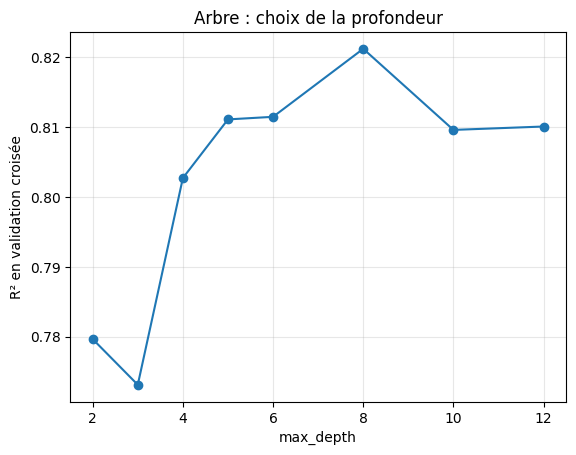

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score

profondeurs = [2, 3, 4, 5, 6, 8, 10, 12]
scores_arbre = []
for p in profondeurs:
    arbre_test = DecisionTreeRegressor(max_depth=p, random_state=42)
    score = cross_val_score(arbre_test, X_train, y_train, cv=5, scoring='r2').mean()
    scores_arbre.append(score)

meilleure_prof = profondeurs[int(np.argmax(scores_arbre))]
print('Profondeur optimale :', meilleure_prof)

plt.plot(profondeurs, scores_arbre, marker='o')
plt.xlabel('max_depth')
plt.ylabel('R² en validation croisée')
plt.title('Arbre : choix de la profondeur')
plt.grid(alpha=0.3); plt.show()

→ Grâce à cela, on peut choisir le paramètre max_depth le plus optimal pour entrainer le modèle de l'arbre. (le point le plus haut du graph)

In [ ]:
arbre = DecisionTreeRegressor(max_depth=meilleure_prof, random_state=42).fit(X_train, y_train)
pred_arbre = np.exp(arbre.predict(X_test))
evaluer('Arbre de décision', reel_test, pred_arbre, resultats)
preds['Arbre de décision'] = pred_arbre

Arbre de décision -> RMSE = 2722.06 | MAE = 1853.67 | R² = 0.939


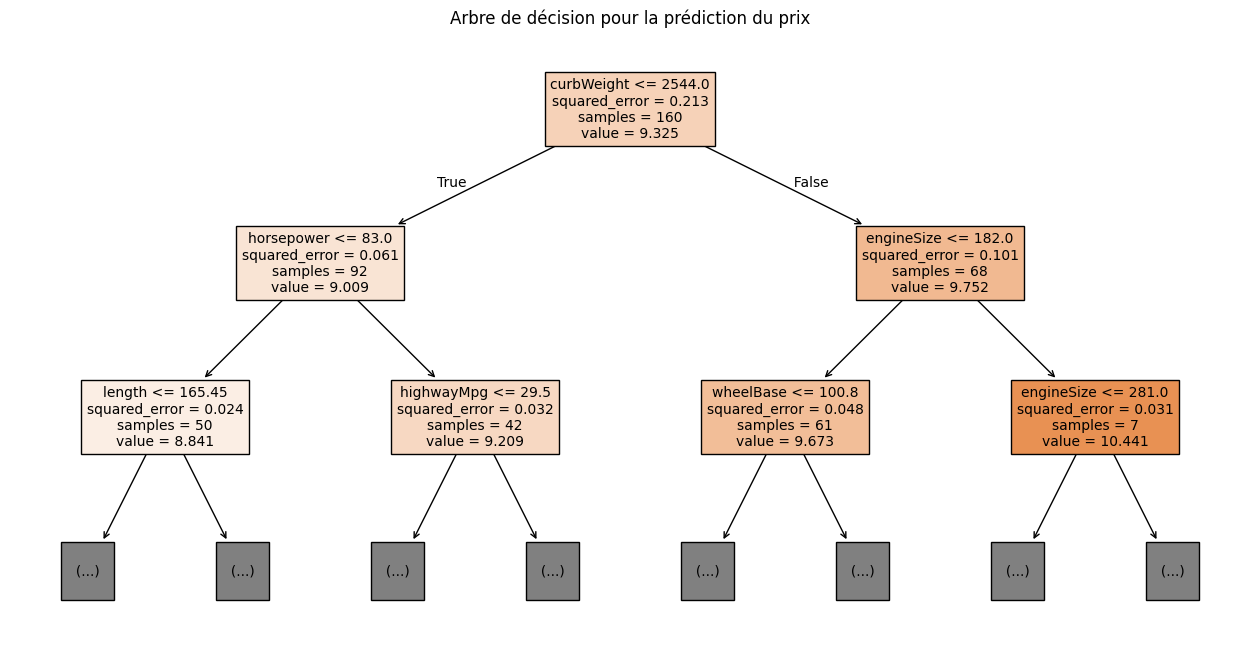

In [41]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


plt.figure(figsize=(16, 8))
plot_tree(
    arbre,
    feature_names=X_train.columns,
    filled=True,
    max_depth=2,                     # LIMITE la profondeur visuelle
    fontsize=10
)
plt.title("Arbre de décision pour la prédiction du prix")
plt.show()

→ La visualisation de l'arbre de décision montre que les variables les plus déterminantes pour la prédiction du prix (situées aux premiers nœuds) sont CurbWeight, engineSize et horsepower. Cela confirme l'analyse de corrélation faite précédemment.

11. Enfin on peut réaliser le dernier modèle 5: La forêt aléatoire.

→ Son hyperparamètre est max_features (fraction de variables considérées à chaque découpe)

- petit = arbres très différents (plus de diversité)
- grand = arbres plus proches.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

fractions = [0.2, 0.33, 0.5, 0.75, 1.0]
scores_rf = []
for f in fractions:
    rf_test = RandomForestRegressor(n_estimators=300, max_features=f, random_state=42, n_jobs=-1)
    score = cross_val_score(rf_test, X_train, y_train, cv=5, scoring='r2').mean()
    scores_rf.append(score)

meilleure_frac = fractions[int(np.argmax(scores_rf))]
print('max_features optimal :', meilleure_frac)
print([round(s, 3) for s in scores_rf])

max_features optimal : 0.33
[np.float64(0.891), np.float64(0.893), np.float64(0.889), np.float64(0.883), np.float64(0.881)]


→ Les scores affichés sont dans le même ordre que la liste fraction.

→ max_features optimal de 0.33 donne un score de 0.893.

In [ ]:
rf = RandomForestRegressor(n_estimators=300, max_features=meilleure_frac, random_state=42, n_jobs=-1).fit(X_train, y_train)
pred_rf = np.exp(rf.predict(X_test))
evaluer('Forêt aléatoire', reel_test, pred_rf, resultats)
preds['Forêt aléatoire'] = pred_rf

Forêt aléatoire -> RMSE = 3887.91 | MAE = 2406.42 | R² = 0.876


12. Nous pouvons maintenant comparer les modèles.

,Modèle,MAE,R²,RMSE
0,Lasso,1380.929,0.961,2183.526
1,Ridge,1578.022,0.942,2669.042
2,Arbre de décision,1853.666,0.939,2722.064
3,Régression linéaire,1749.874,0.928,2960.899
4,Forêt aléatoire,2406.419,0.876,3887.913


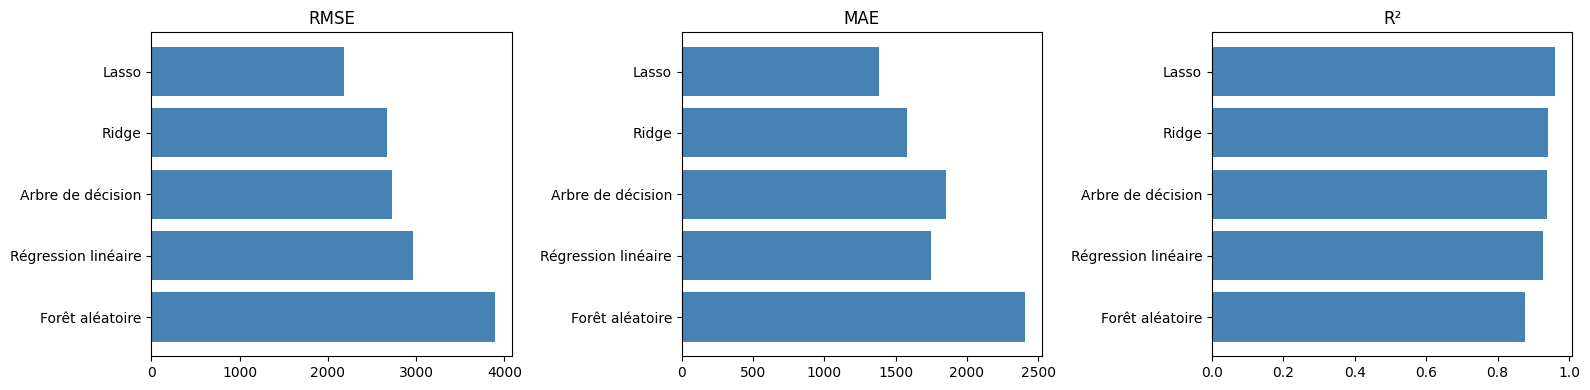

In [ ]:
tableau = pd.DataFrame(resultats).sort_values('RMSE').reset_index(drop=True)
display(tableau.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, m in enumerate(['RMSE', 'MAE', 'R²']):
    ax[i].barh(tableau['Modèle'], tableau[m], color='steelblue')
    ax[i].set_title(m); ax[i].invert_yaxis()
plt.tight_layout()
plt.show()

→ J'observe que le Lasso possède le RMSE le plus faible. Sa MAE est également la moins importante de tous les modèles. Son R² est le plus grand de tous les modèles.

→ Grâce à ses graphiques, je conclue que Lasso est le modèle le plus adapté pour ce dataset imports85.csv.

Meilleur modèle (RMSE le plus faible) : Lasso


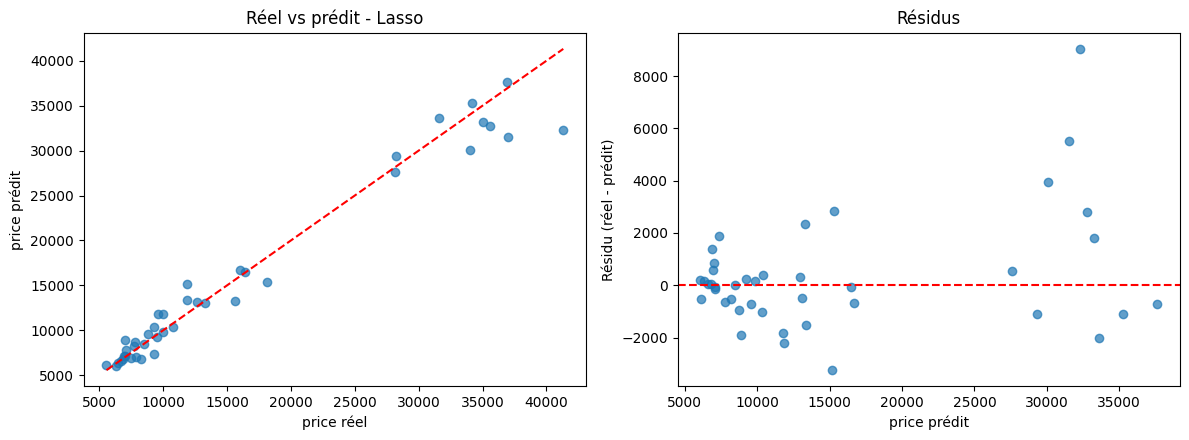

In [ ]:
meilleur = tableau.loc[0, 'Modèle']
print('Meilleur modèle (RMSE le plus faible) :', meilleur)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(preds['Réel'], preds[meilleur], alpha=0.7)
mini, maxi = preds['Réel'].min(), preds['Réel'].max()
ax[0].plot([mini, maxi], [mini, maxi], 'r--')
ax[0].set_xlabel('price réel'); ax[0].set_ylabel('price prédit'); ax[0].set_title('Réel vs prédit - ' + meilleur)

residus = preds['Réel'] - preds[meilleur]
ax[1].scatter(preds[meilleur], residus, alpha=0.7)
ax[1].axhline(0, color='r', linestyle='--')
ax[1].set_xlabel('price prédit'); ax[1].set_ylabel('Résidu (réel - prédit)'); ax[1].set_title('Résidus')
plt.tight_layout(); plt.show()

* Pour le graph de gauche, j'affiche la cible réel en fonction de la cible
prédite. Les points doivent le plus possible se rapprocher de la diagonale pour prouver que mon modèle fonctionne bien sur les données de test.
On peut voir qu'a l'exception de certains points, Lasso à l'air de correctement prédire mes données cibles.


* Pour le graph de droite, j'affiche la cible prédite en fonction du résidu. Je veux que l'erreur entre ma prédiction et la cible soit la plus proche de 0. Je cherche à ce que les points se rapporchent le plus possible du trait rouge 0. Encore une fois à l'exception de certains points, on peut obverser une grande majorité de point proche de la ligne 0.

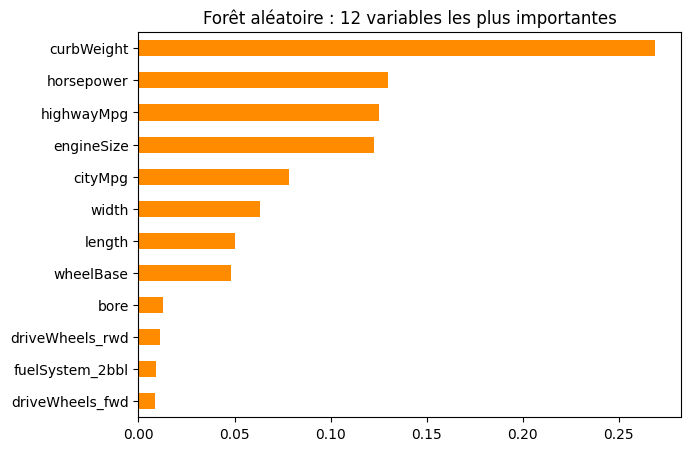

In [ ]:
# Variables les plus importantes selon la forêt aléatoire
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)
importances.sort_values().plot(kind='barh', color='darkorange', figsize=(7, 5))
plt.title('Forêt aléatoire : 12 variables les plus importantes'); plt.show()

→ On peut remarquer que Le Lasso retient 31 variables sur 63, dominées par curbWeight. La forêt aléatoire, qui est un modèle d’une autre famille, classe aussi curbWeight en premier, ce qui confirme que le poids est le principal déterminant du prix.

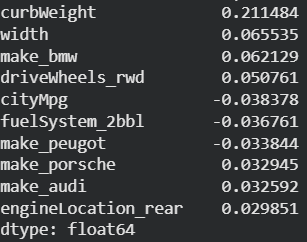

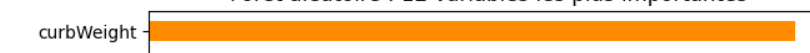

---
# **PARTIE 2: "Hitters.csv"**

***2) On utilise les données « Hitters » fournies. On souhaite prédire la variable « Salary » à l’aide des autres variables. Proposer plusieurs algorithmes de prédiction de cette variable et les comparer.***

1. Je commence par charger les données.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

hitters = pd.read_csv("/content/drive/MyDrive/Machine Learning/evaluation/Hitters.csv", sep=";", decimal=',', na_values='NA')
print(hitters.shape)
hitters.head()

(322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


2. J'explore les données.

In [ ]:
quanti_h = hitters.select_dtypes(include='number').columns.tolist()
quali_h = hitters.select_dtypes(exclude='number').columns.tolist()
print('Quantitatives :', quanti_h)
print('Qualitatives  :', quali_h)
hitters.describe().T.round(2)

Quantitatives : ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'PutOuts', 'Assists', 'Errors', 'Salary']
Qualitatives  : ['League', 'Division', 'NewLeague']


,count,mean,std,min,25%,50%,75%,max
AtBat,322.0,380.93,153.40,16.0,255.25,379.5,512.00,687.0
Hits,322.0,101.02,46.45,1.0,64.00,96.0,137.00,238.0
HmRun,322.0,10.77,8.71,0.0,4.00,8.0,16.00,40.0
Runs,322.0,50.91,26.02,0.0,30.25,48.0,69.00,130.0
RBI,322.0,48.03,26.17,0.0,28.00,44.0,64.75,121.0
Walks,322.0,38.74,21.64,0.0,22.00,35.0,53.00,105.0
Years,322.0,7.44,4.93,1.0,4.00,6.0,11.00,24.0
CAtBat,322.0,2648.68,2324.21,19.0,816.75,1928.0,3924.25,14053.0
CHits,322.0,717.57,654.47,4.0,209.00,508.0,1059.25,4256.0
CHmRun,322.0,69.49,86.27,0.0,14.00,37.5,90.00,548.0


→ Je vois que ma cible "Salary" est quantitative.

→ Certaines données explicatives sont qualitatives, je dois les transformer en variables indcatrices avec get_dummies.

count     263.0
mean      535.9
std       451.1
min        67.5
25%       190.0
50%       425.0
75%       750.0
max      2460.0
Name: Salary, dtype: float64

Asymétrie de Salary      : 1.59
Asymétrie de log(Salary) : -0.18


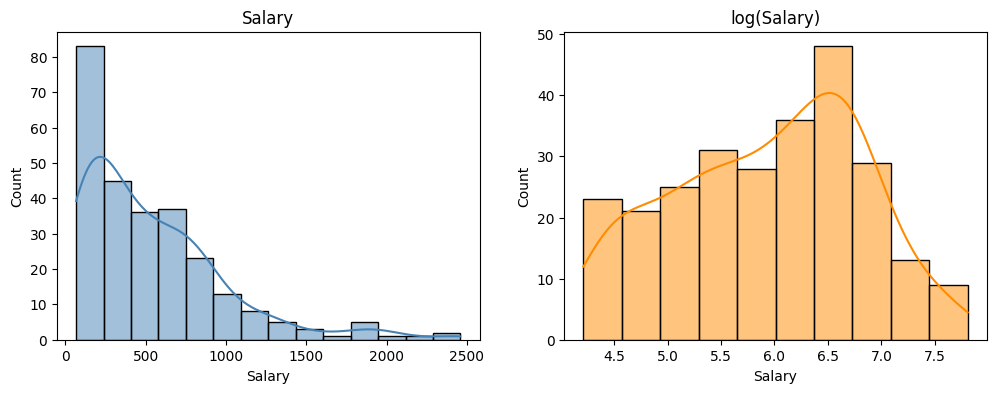

In [ ]:
print(hitters['Salary'].describe().round(1))
print()
print('Asymétrie de Salary      :', round(hitters['Salary'].skew(), 2))
print('Asymétrie de log(Salary) :', round(np.log(hitters['Salary'].dropna()).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(hitters['Salary'].dropna(), kde=True, ax=ax[0], color='steelblue'); ax[0].set_title('Salary')
sns.histplot(np.log(hitters['Salary'].dropna()), kde=True, ax=ax[1], color='darkorange'); ax[1].set_title('log(Salary)')
plt.show()

→ Je remarque que la distribution de la variable cible Salary est asymétrique à droite et donc passer au log parait utile puisqu'il rend la distribution plus symétrique.

→ Il faudra que je repasse en exponentielle à la fin pour les calculs de métriques.

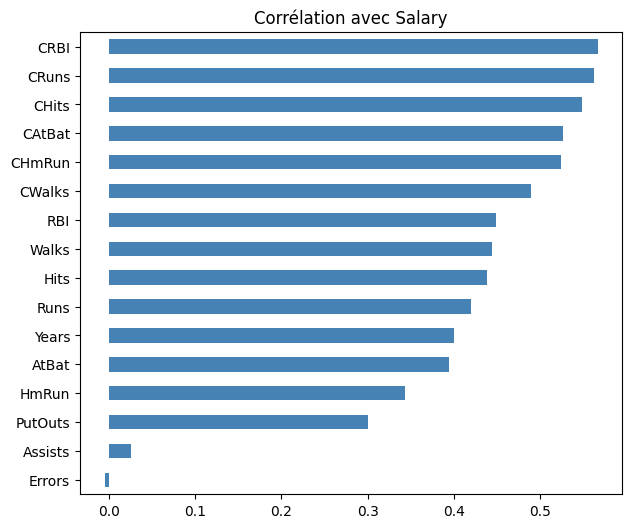

In [ ]:
correl_h = hitters[quanti_h].corr()['Salary'].drop('Salary').sort_values()
correl_h.plot(kind='barh', figsize=(7, 6), color='steelblue')
plt.title('Corrélation avec Salary'); plt.show()

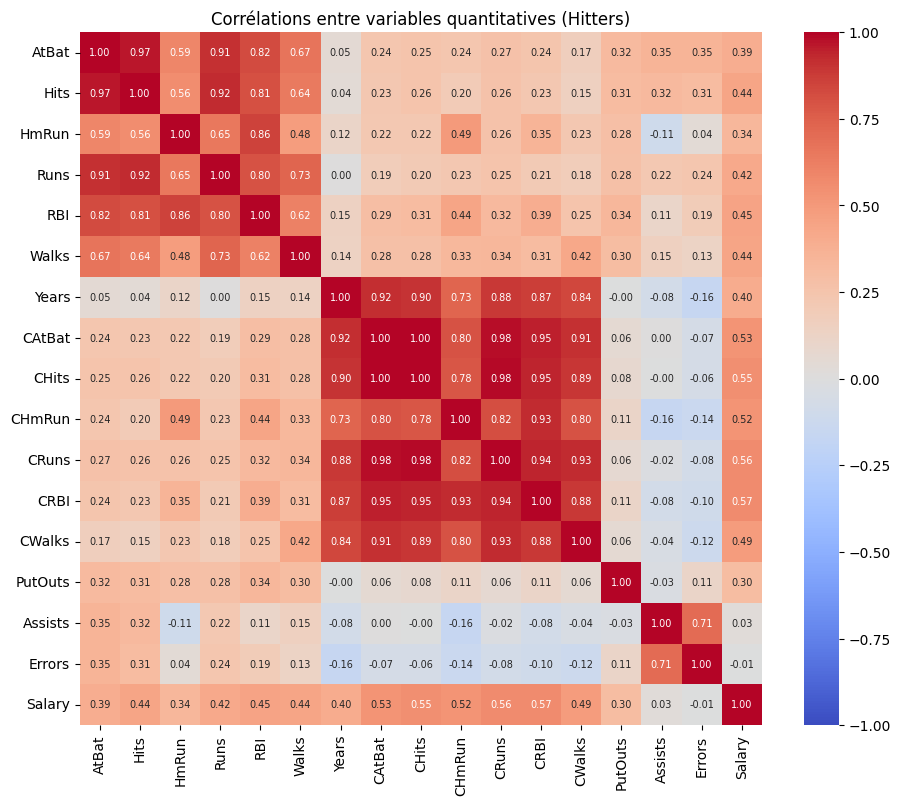

In [ ]:
corr_h = hitters[quanti_h].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_h, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Corrélations entre variables quantitatives (Hitters)')
plt.show()

→ On peut observer que beaucoup de données sont très corrélées entre elles.

→ Conséquence pour les modèles :

- Pour la régression linéaire simple, les coefficients sont instables et difficiles à interpréter. Deux variables presque identiques se « partagent » l’effet de façon arbitraire.

- Pour Ridge et Lasso, c’est exactement la situation où la pénalisation aide. Ridge répartit l’effet entre les variables corrélées, et le Lasso en garde une seule (ici CHits) et met les autres à 0.

- Pour la forêt, elle partage l’importance entre les variables quasi identiques. C’est pour ça que CAtBat, CRuns, CHits, CWalks et CRBI auront chacun environ la même importance

3. J'analyse maintenant la qualité des données : est-ce qu'il manque des valeurs.

In [ ]:
manq_h = hitters.isna().sum()
manq_h = manq_h[manq_h > 0]
pd.DataFrame({'nb manquants': manq_h, '% manquants': (manq_h / len(hitters) * 100).round(1)})

,nb manquants,% manquants
Salary,59,18.3


→ Seule la cible Salary a des valeurs manquantes.

→ Il n'y a pas le choix que de supprimer les lignes, car on ne peut pas inventer ou remplacer la variables cibles. A noter que cela représente tout de même 18,3% du Dataset.

In [ ]:
df_clean_h = hitters.dropna(subset=['Salary']).copy()
print('Lignes restantes :', df_clean_h.shape[0])
print('Manquants restants :', int(df_clean_h.isna().sum().sum()))

Lignes restantes : 263
Manquants restants : 0


→ Il nous reste donc 263 joueurs dans le dataset pour effectuer nos prédictions. Cela reste correcte.

4. Je passe maintenant au découpage en Train/Test et à la standardisation des données.

→ Je vais découper mes données en 80% apprentissage et 20% test.

→ Je vais standardiser car cela est ensentiel pour les algorithmes de Ridge et Lasso traités plus loin.

In [ ]:
y_h = np.log(df_clean_h['Salary'])                       # cible transformée en log
X_h = pd.get_dummies(df_clean_h.drop(columns=['Salary']), drop_first=True).astype(float) #variables qualitatives transformées

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_h, y_h, test_size=0.2, random_state=42)


# standardisation (pour les modèles linéaires)
scaler_h = StandardScaler()
X_train_sc_h = scaler_h.fit_transform(X_train_h)
X_test_sc_h = scaler_h.transform(X_test_h)

# vraie valeur de la cible dans son unité d'origine (pour calculer les métriques)
reel_test_h = np.exp(y_test_h)

print('Variables explicatives après encodage :', X_h.shape[1])
print('Train :', X_train_h.shape[0], 'lignes | Test :', X_test_h.shape[0], 'lignes')

# tableaux qui vont stocker les résultats
resultats_h = []
preds_h = pd.DataFrame({'Réel': reel_test_h.values})

Variables explicatives après encodage : 19
Train : 210 lignes | Test : 53 lignes


5. Je m'occupe ensuite des métriques d'évaluation de la régression.

→ Toutes ces métriques seront calculées dans l'unité d'origine de la cible price, donc je dois utiliser np.exp(log(price)).

→ Les métriques de la régression sont MAE, R² et RMSE.

In [ ]:
def evaluer(nom, y_reel, y_pred, tableau):
    rmse = np.sqrt(mean_squared_error(y_reel, y_pred))
    mae = mean_absolute_error(y_reel, y_pred)
    r2 = r2_score(y_reel, y_pred)
    tableau.append({'Modèle': nom, 'RMSE': rmse, 'MAE': mae, 'R²': r2})
    print(f"{nom} -> RMSE = {rmse:.2f} | MAE = {mae:.2f} | R² = {r2:.3f}")

6. Je peux maintenant passer au modèle 1 : la régression linéaire.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lin_h = LinearRegression().fit(X_train_sc_h, y_train_h)
pred_lin_h = np.exp(lin_h.predict(X_test_sc_h))
evaluer('Régression linéaire', reel_test_h, pred_lin_h, resultats_h)
preds_h['Régression linéaire'] = pred_lin_h

Régression linéaire -> RMSE = 370.76 | MAE = 225.25 | R² = 0.240


7. Je passe ensuite au modèle 2 : le modèle Ridge (pénalisation L2).

→ Ce modèle à un hyperparamètre à régler : alpha .

→ Pour trouver le alpha optimal : RidgeCV teste 50 valeurs de  α  (de 0,001 à 1000 par exemple) et garde celle qui donne la meilleure validation croisée à 5 plis sur le train.

In [ ]:
ridge_h = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_sc_h, y_train_h)
print('alpha optimal (Ridge) :', round(ridge_h.alpha_, 4))
pred_ridge_h = np.exp(ridge_h.predict(X_test_sc_h))
evaluer('Ridge', reel_test_h, pred_ridge_h, resultats_h)
preds_h['Ridge'] = pred_ridge_h

alpha optimal (Ridge) : 79.0604
Ridge -> RMSE = 362.18 | MAE = 215.09 | R² = 0.275


8. Je passe ensuite au modèle 3 : Lasso (pénalisation L1).

→ Lasso choisit également son hyperparamètre alpha par validation croisé sur 5 plis.

In [ ]:
lasso_h = LassoCV(cv=5, random_state=42, max_iter=50000).fit(X_train_sc_h, y_train_h)
print('alpha optimal (Lasso) :', round(lasso_h.alpha_, 5))
nb_non_nuls_h = int(np.sum(lasso_h.coef_ != 0))
print('Variables conservées :', nb_non_nuls_h, 'sur', X_train_sc_h.shape[1])
pred_lasso_h = np.exp(lasso_h.predict(X_test_sc_h))
evaluer('Lasso', reel_test_h, pred_lasso_h, resultats_h)
preds_h['Lasso'] = pred_lasso_h

# variables retenues par le Lasso (coefficient != 0)
coef_lasso_h = pd.Series(lasso_h.coef_, index=X_train_h.columns)
print(coef_lasso_h[coef_lasso_h != 0].sort_values(key=abs, ascending=False).head(10))

alpha optimal (Lasso) : 0.02142
Variables conservées : 9 sur 19
Lasso -> RMSE = 369.47 | MAE = 225.62 | R² = 0.245
Years         0.306107
Hits          0.278902
CHits         0.160722
Walks         0.080301
Division_W   -0.076546
PutOuts       0.057886
HmRun         0.052323
League_N      0.038769
Errors       -0.023326
dtype: float64


9. Je passe ensuite au modèle 4 : l'arbre de décision

→ Ce modèle n'utilise pas les données standardiser.

→ Son hyperparamrètre est max_depth (nombre maximal de questions successives).

- btrop petit → arbre trop simple (sous-apprentissage) ;
- trop grand → arbre qui apprend le bruit (surapprentissage).

→ On teste plusieurs profondeurs par validation croisée (5 plis, R²) et on garde la meilleure.

Profondeur optimale : 3


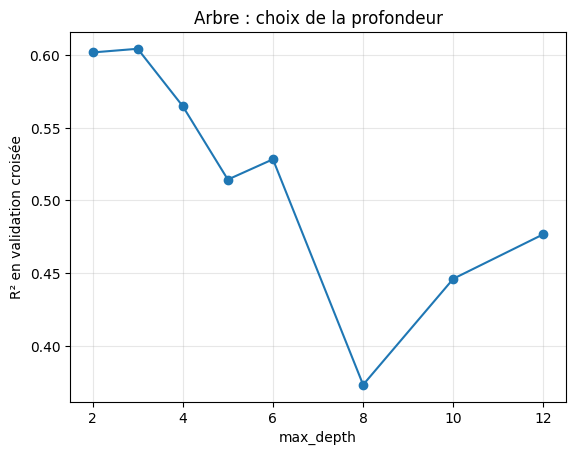

In [ ]:
profondeurs_h = [2, 3, 4, 5, 6, 8, 10, 12]
scores_arbre_h = []
for p in profondeurs_h:
    arbre_test = DecisionTreeRegressor(max_depth=p, random_state=42)
    score = cross_val_score(arbre_test, X_train_h, y_train_h, cv=5, scoring='r2').mean()
    scores_arbre_h.append(score)

meilleure_prof_h = profondeurs_h[int(np.argmax(scores_arbre_h))]
print('Profondeur optimale :', meilleure_prof_h)

plt.plot(profondeurs_h, scores_arbre_h, marker='o')
plt.xlabel('max_depth'); plt.ylabel('R² en validation croisée'); plt.title('Arbre : choix de la profondeur')
plt.grid(alpha=0.3); plt.show()

→ Grâce à cela, on peut choisir le paramètre max_depth le plus optimal pour entrainer le modèle de l'arbre. (le point le plus haut du graph)

In [ ]:
arbre_h = DecisionTreeRegressor(max_depth=meilleure_prof_h, random_state=42).fit(X_train_h, y_train_h)
pred_arbre_h = np.exp(arbre_h.predict(X_test_h))
evaluer('Arbre de décision', reel_test_h, pred_arbre_h, resultats_h)
preds_h['Arbre de décision'] = pred_arbre_h

Arbre de décision -> RMSE = 376.98 | MAE = 206.37 | R² = 0.214


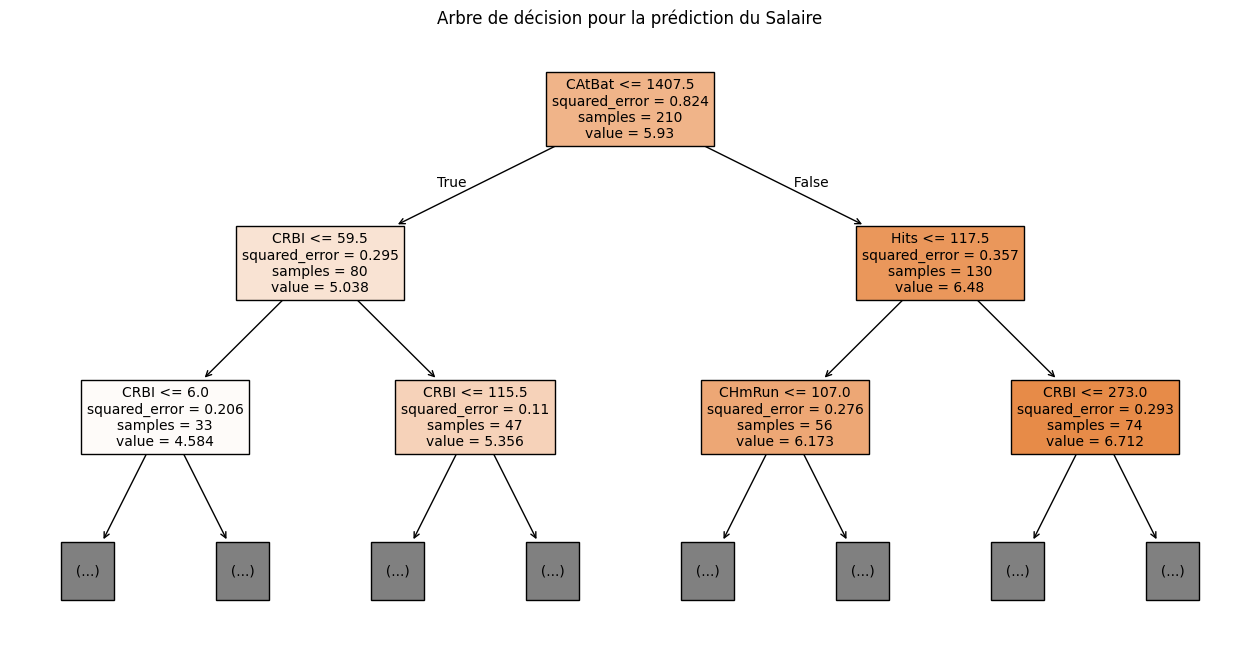

In [43]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


plt.figure(figsize=(16, 8))
plot_tree(
    arbre_h,
    feature_names=X_train_h.columns,
    filled=True,
    max_depth=2,                     # LIMITE la profondeur visuelle
    fontsize=10
)
plt.title("Arbre de décision pour la prédiction du Salaire")
plt.show()

→ On voit bien que des variables telles que CatBat, CRBI ou Hits sont des variables de poids dans la décision pour prédire Salary.

10. Enfin on peut réaliser le dernier modèle 5: La forêt aléatoire.

→ Son hyperparamètre est max_features (fraction de variables considérées à chaque découpe)

- petit = arbres très différents (plus de diversité)
- grand = arbres plus proches.

In [ ]:
fractions_h = [0.2, 0.33, 0.5, 0.75, 1.0]
scores_rf_h = []
for f in fractions_h:
    rf_test = RandomForestRegressor(n_estimators=300, max_features=f, random_state=42, n_jobs=-1)
    score = cross_val_score(rf_test, X_train_h, y_train_h, cv=5, scoring='r2').mean()
    scores_rf_h.append(score)

meilleure_frac_h = fractions_h[int(np.argmax(scores_rf_h))]
print('max_features optimal :', meilleure_frac_h)
print([round(s, 3) for s in scores_rf_h])

max_features optimal : 0.2
[np.float64(0.747), np.float64(0.745), np.float64(0.741), np.float64(0.734), np.float64(0.729)]


→ Les scores affichés sont dans le même ordre que la liste fraction.

→ max_features optimal de 0.2 donne un score de 0.747.

In [ ]:
rf_h = RandomForestRegressor(n_estimators=300, max_features=meilleure_frac_h, random_state=42, n_jobs=-1).fit(X_train_h, y_train_h)
pred_rf_h = np.exp(rf_h.predict(X_test_h))
evaluer('Forêt aléatoire', reel_test_h, pred_rf_h, resultats_h)
preds_h['Forêt aléatoire'] = pred_rf_h

Forêt aléatoire -> RMSE = 336.57 | MAE = 167.32 | R² = 0.374


11. Nous pouvons maintenant comparé les modèles.

,Modèle,RMSE,MAE,R²
0,Forêt aléatoire,336.573,167.316,0.374
1,Ridge,362.176,215.091,0.275
2,Lasso,369.468,225.624,0.245
3,Régression linéaire,370.764,225.250,0.240
4,Arbre de décision,376.983,206.369,0.214


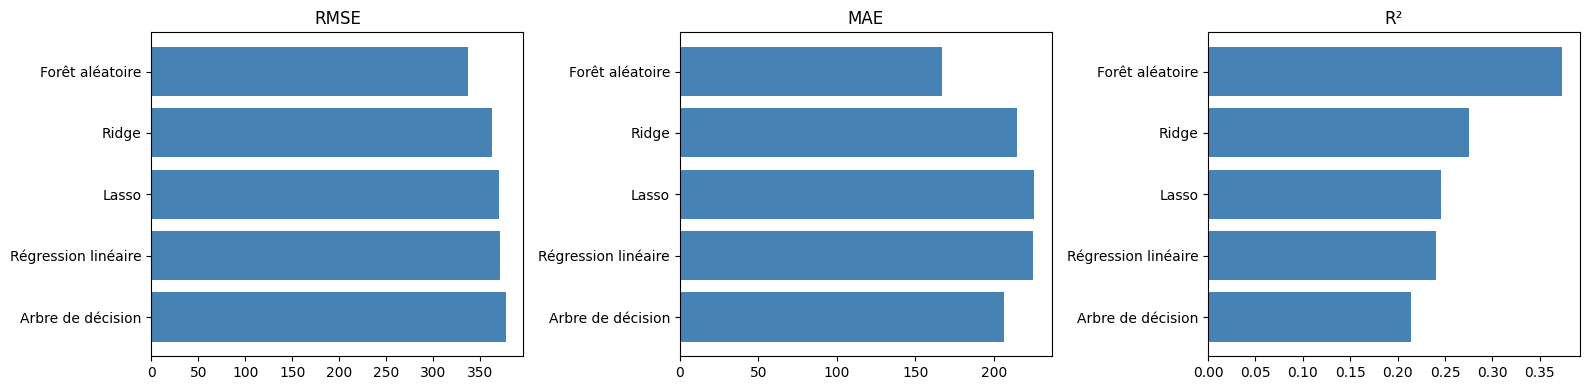

In [ ]:
tableau_h = pd.DataFrame(resultats_h).sort_values('RMSE').reset_index(drop=True)
display(tableau_h.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, m in enumerate(['RMSE', 'MAE', 'R²']):
    ax[i].barh(tableau_h['Modèle'], tableau_h[m], color='steelblue')
    ax[i].set_title(m); ax[i].invert_yaxis()
plt.tight_layout(); plt.show()

→ J'observe que La forêt aléatoire possède le RMSE le plus faible. Sa MAE est également la moins importante de tous les modèles. Son R² est le plus grand de tous les modèles

→ Grâce à ses graphiques, je conclue que La Forêt Aléatoire est le modèle le plus adapté pour ce dataset Hatters.csv.

Meilleur modèle (RMSE le plus faible) : Forêt aléatoire


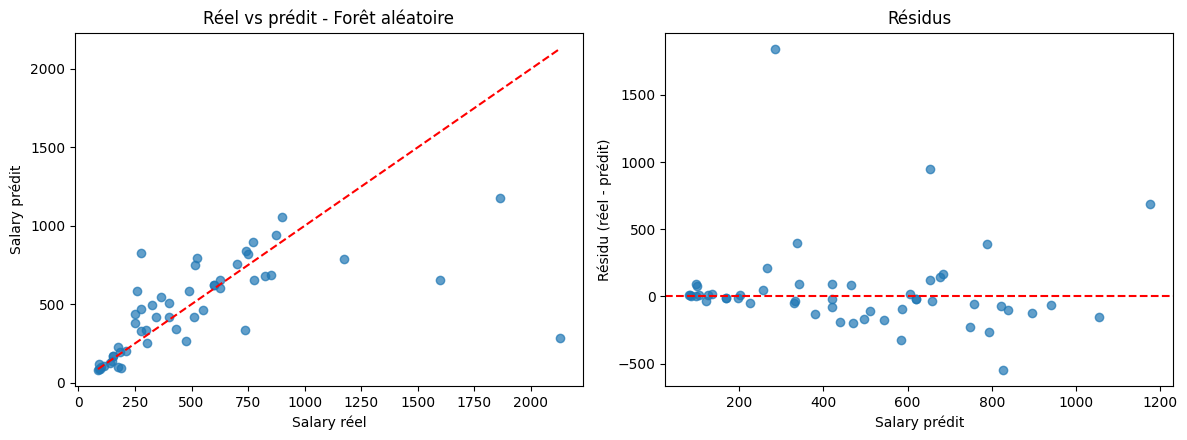

In [ ]:
meilleur_h = tableau_h.loc[0, 'Modèle']
print('Meilleur modèle (RMSE le plus faible) :', meilleur_h)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(preds_h['Réel'], preds_h[meilleur_h], alpha=0.7)
mini, maxi = preds_h['Réel'].min(), preds_h['Réel'].max()
ax[0].plot([mini, maxi], [mini, maxi], 'r--')
ax[0].set_xlabel('Salary réel'); ax[0].set_ylabel('Salary prédit'); ax[0].set_title('Réel vs prédit - ' + meilleur_h)

residus_h = preds_h['Réel'] - preds_h[meilleur_h]
ax[1].scatter(preds_h[meilleur_h], residus_h, alpha=0.7)
ax[1].axhline(0, color='r', linestyle='--')
ax[1].set_xlabel('Salary prédit'); ax[1].set_ylabel('Résidu (réel - prédit)'); ax[1].set_title('Résidus')
plt.tight_layout(); plt.show()

* Pour le graph de gauche, j'affiche la cible réel en fonction de la cible
prédite. Les points doivent le plus possible se rapprocher de la diagonale pour prouver que mon modèle fonctionne bien sur les données de test.
On peut voir qu'a l'exception de certains points, la Forêt à l'air de correctement prédire mes données cibles.


* Pour le graph de droite, j'affiche la cible prédite en fonction du résidu. Je veux que l'erreur entre ma prédiction et la cible soit la plus proche de 0. Je cherche à ce que les points se rapporchent le plus possible du trait rouge 0. Encore une fois à l'exception de certains points, on peut obverser une grande majorité de point proche de la ligne 0.

→→→ On peut souligner que parmis les deux exercices basés sur 2 datasets différents, le modèle du dataset imports85.csv le plus optimal était Lasso.
Pour le modèle du dataset Hitters.csv le plus optimal nous avions La Forêt Aléatoire.

Même si les deux modèles sont les plus optimaux pour leur dataset respectif, la forêt aléatoire donne de très bon résultats, visibles sur les deux derniers graph. En effet, les données du graph de gauche colle énormément à la prédiction représentée par la ligne pointillée rouge; et les données du graph de droite sont très proche de la ligne pointilée rouge représentant le 0, ce qui est recherché.

Ces résultats sont meilleurs visuellement chez la Forêt Aléatoire dans l'exercice 2 que pour Lasso dans l'exercice 1.